# CV5570 - Computer Vision for Construction Engineering Asssignment 2
## Object Detection

### Import the Necessary Packages

In [ ]:
import os
import json
import time
import random
from pathlib import Path
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import cv2
from PIL import Image

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)
import torchmetrics
from torchmetrics.detection import MeanAveragePrecision
from ultralytics import YOLO
from transformers import (
    DetrImageProcessor,
    DetrForObjectDetection
)
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

d:\CV5570\CV5570_Assignment_2\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### Checking CUDA and GPU availability & versions

In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Packages imported successfully.")
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Packages imported successfully.
PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
CUDA available: True
CUDA version: 13.0
GPU: NVIDIA GeForce RTX 4070 Laptop GPU


### Dataset Acquisition and Preprocessing

#### Dataset Loading and Annotation Format

The Annotated Construction Images Dataset (ACID) is used for the object detection experiments. As specified in the assignment, the experiments are restricted to three construction equipment classes:

- Excavator
- Dozer
- Dump Truck

The dataset contains the images in the `dataset/images/` directory. Annotations are provided in both CSV and JSON formats. The CSV file contains the image filename, image dimensions, object class, and bounding-box coordinates, while the JSON file follows a structured image-annotation-category format.

The CSV annotations are used as the primary annotation source for dataset analysis because the bounding-box information is directly available in tabular form.

In [8]:
DATASET_DIR = Path("./dataset")
IMAGE_DIR = DATASET_DIR / "images"

CSV_PATH = DATASET_DIR / "3classes.csv"
JSON_PATH = DATASET_DIR / "3classes.json"

required_paths = {
    "Dataset directory": DATASET_DIR,
    "Image directory": IMAGE_DIR,
    "CSV annotation file": CSV_PATH,
    "JSON annotation file": JSON_PATH
}

for name, path in required_paths.items():
    if not path.exists():
        raise FileNotFoundError(f"{name} not found: {path}")

print("Dataset paths verified successfully.")
print("Image directory:", IMAGE_DIR)
print("CSV annotations:", CSV_PATH)
print("JSON annotations:", JSON_PATH)

Dataset paths verified successfully.
Image directory: dataset\images
CSV annotations: dataset\3classes.csv
JSON annotations: dataset\3classes.json


In [9]:
annotations_df = pd.read_csv(CSV_PATH)

print("Annotation dataframe shape:", annotations_df.shape)

print("\nAnnotation columns:")
print(annotations_df.columns.tolist())

print("\nFirst five annotation records:")
display(annotations_df.head())

Annotation dataframe shape: (7614, 9)

Annotation columns:
['Unnamed: 0', 'filename', 'width', 'height', 'class', 'xmin', 'ymin', 'xmax', 'ymax']

First five annotation records:


,Unnamed: 0,filename,width,height,class,xmin,ymin,xmax,ymax
0,0,00001.jpg,720,576,excavator,435,225,469,255
1,1,00001.jpg,720,576,excavator,383,241,411,270
2,2,00001.jpg,720,576,excavator,420,267,449,334
3,3,00001.jpg,720,576,excavator,235,247,262,292
4,4,00002.jpg,1280,720,excavator,357,32,995,531


In [10]:
with open(JSON_PATH, "r", encoding="utf-8") as file:
    coco_data = json.load(file)

print("JSON sections:")
print(list(coco_data.keys()))

print("\nNumber of images:", len(coco_data["images"]))
print("Number of annotations:", len(coco_data["annotations"]))

print("\nCategories:")
display(pd.DataFrame(coco_data["categories"]))

JSON sections:
['images', 'categories', 'annotations']

Number of images: 3929
Number of annotations: 7614

Categories:


,supercategory,id,name
0,none,0,None
1,None,1,dozer
2,None,2,dump_truck
3,None,3,excavator


In [11]:
if "Unnamed: 0" in annotations_df.columns:
    annotations_df = annotations_df.drop(columns=["Unnamed: 0"])

CLASS_NAMES = {
    "excavator": "Excavator",
    "dozer": "Dozer",
    "dump_truck": "Dump Truck"
}

annotations_df["class"] = (
    annotations_df["class"]
    .str.lower()
    .str.strip()
)

unexpected_classes = (
    set(annotations_df["class"])
    - set(CLASS_NAMES.keys())
)

if unexpected_classes:
    raise ValueError(
        f"Unexpected classes found: {unexpected_classes}"
    )

annotations_df["class_name"] = (
    annotations_df["class"].map(CLASS_NAMES)
)

print("Classes in the dataset:")
print(
    annotations_df["class_name"]
    .value_counts()
)

Classes in the dataset:
class_name
Dump Truck    3701
Excavator     2790
Dozer         1123
Name: count, dtype: int64


#### Dataset Statistics

The dataset statistics are calculated at both image level and annotation-instance level. The total number of unique images is obtained from the annotation records, while the number of instances represents the total number of annotated objects for each class.

The annotation format and dataset statistics are summarized in a single table for reporting.

In [12]:
total_images = annotations_df["filename"].nunique()
total_instances = len(annotations_df)

class_instance_counts = (
    annotations_df["class_name"]
    .value_counts()
    .reindex(
        ["Excavator", "Dozer", "Dump Truck"]
    )
)

class_image_counts = (
    annotations_df
    .groupby("class_name")["filename"]
    .nunique()
    .reindex(
        ["Excavator", "Dozer", "Dump Truck"]
    )
)

print("Total images:", total_images)
print("Total annotated instances:", total_instances)

Total images: 3929
Total annotated instances: 7614


In [13]:
dataset_summary = pd.DataFrame({
    "Class": [
        "Excavator",
        "Dozer",
        "Dump Truck"
    ],
    "Images Containing Class": class_image_counts.values,
    "Instances": class_instance_counts.values
})

display(dataset_summary)

,Class,Images Containing Class,Instances
0,Excavator,2239,2790
1,Dozer,1025,1123
2,Dump Truck,2206,3701


In [14]:
dataset_summary = pd.DataFrame({
    "Class": [
        "Excavator",
        "Dozer",
        "Dump Truck"
    ],
    "Images Containing Class": class_image_counts.values,
    "Instances": class_instance_counts.values
})

display(dataset_summary)

,Class,Images Containing Class,Instances
0,Excavator,2239,2790
1,Dozer,1025,1123
2,Dump Truck,2206,3701


#### Class Distribution

The class distribution is analyzed using the number of annotated instances belonging to each equipment category. A bar chart is used to visualize the frequency of Excavators, Dozers, and Dump Trucks in the dataset.

This analysis also provides an indication of the class imbalance that may affect detector training and per-class detection performance.

In [15]:
class_counts = (
    annotations_df["class_name"]
    .value_counts()
    .reindex(
        ["Excavator", "Dozer", "Dump Truck"]
    )
)

display(
    class_counts.to_frame(
        name="Number of Instances"
    )
)

,Number of Instances
class_name,
Excavator,2790
Dozer,1123
Dump Truck,3701


In [18]:
RESULTS_DIR = Path("./notebook_results")

SECTION_2_RESULTS_DIR = (
    RESULTS_DIR / "dataset_acquisition_and_preprocessing"
)

SECTION_2_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "Section 2 results directory:",
    SECTION_2_RESULTS_DIR
)

Section 2 results directory: notebook_results\dataset_acquisition_and_preprocessing


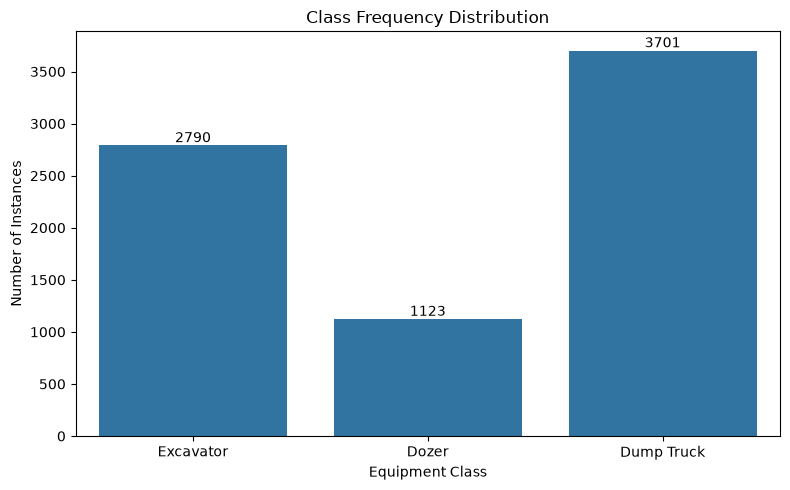

Saved: notebook_results\dataset_acquisition_and_preprocessing\class_distribution.png


In [19]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Class Frequency Distribution")
plt.xlabel("Equipment Class")
plt.ylabel("Number of Instances")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d"
    )

plt.tight_layout()

class_distribution_path = (
    SECTION_2_RESULTS_DIR / "class_distribution.png"
)

plt.savefig(
    class_distribution_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    class_distribution_path
)

#### Bounding Box Analysis

Bounding-box dimensions are analyzed to understand the spatial characteristics of the annotated construction equipment.

For each annotation, the following quantities are calculated:

- Bounding-box width
- Bounding-box height
- Bounding-box area
- Bounding-box aspect ratio
- Bounding-box area relative to the image area

The distributions are visualized using histograms.

In [20]:
annotations_df["bbox_width"] = (
    annotations_df["xmax"]
    - annotations_df["xmin"]
)

annotations_df["bbox_height"] = (
    annotations_df["ymax"]
    - annotations_df["ymin"]
)

annotations_df["bbox_area"] = (
    annotations_df["bbox_width"]
    * annotations_df["bbox_height"]
)

annotations_df["image_area"] = (
    annotations_df["width"]
    * annotations_df["height"]
)

annotations_df["bbox_area_ratio"] = (
    annotations_df["bbox_area"]
    / annotations_df["image_area"]
)

annotations_df["bbox_aspect_ratio"] = (
    annotations_df["bbox_width"]
    / annotations_df["bbox_height"]
)

In [21]:
invalid_boxes = annotations_df[
    (annotations_df["xmin"] >= annotations_df["xmax"]) |
    (annotations_df["ymin"] >= annotations_df["ymax"]) |
    (annotations_df["xmin"] < 0) |
    (annotations_df["ymin"] < 0) |
    (annotations_df["xmax"] > annotations_df["width"]) |
    (annotations_df["ymax"] > annotations_df["height"])
]

print("Total bounding boxes:", len(annotations_df))
print("Invalid bounding boxes:", len(invalid_boxes))

if len(invalid_boxes) > 0:
    display(invalid_boxes.head())

Total bounding boxes: 7614
Invalid bounding boxes: 0


In [22]:
bbox_statistics = annotations_df[
    [
        "bbox_width",
        "bbox_height",
        "bbox_area",
        "bbox_area_ratio",
        "bbox_aspect_ratio"
    ]
].describe()

display(bbox_statistics)

,bbox_width,bbox_height,bbox_area,bbox_area_ratio,bbox_aspect_ratio
count,7614.000000,7614.00000,7.614000e+03,7614.000000,7614.000000
mean,391.447071,271.63751,1.588830e+05,0.168456,1.509138
std,310.128722,198.92941,2.972977e+05,0.200600,0.656343
min,12.000000,10.00000,1.300000e+02,0.000212,0.163978
25%,163.000000,120.00000,2.016450e+04,0.022800,1.067921
50%,316.000000,228.00000,7.314200e+04,0.088101,1.448696
75%,543.000000,383.00000,1.998875e+05,0.240442,1.836389
max,3768.000000,2696.00000,9.457680e+06,0.990117,20.900000


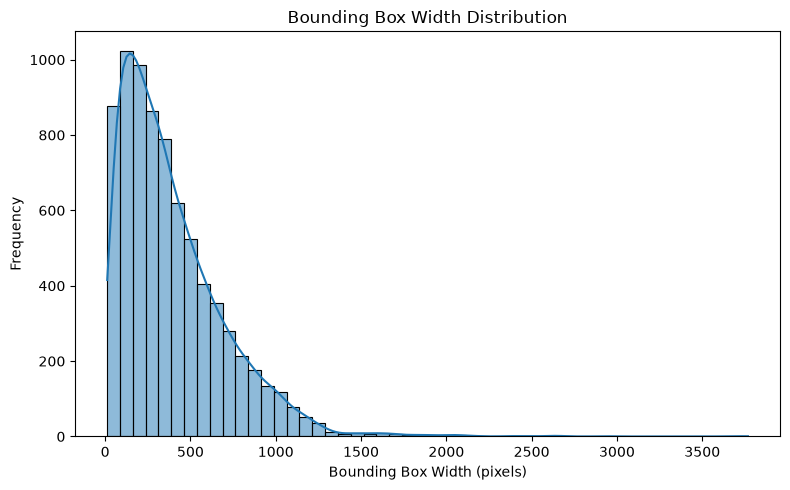

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=annotations_df,
    x="bbox_width",
    bins=50,
    kde=True
)

plt.title("Bounding Box Width Distribution")
plt.xlabel("Bounding Box Width (pixels)")
plt.ylabel("Frequency")

plt.tight_layout()

path = SECTION_2_RESULTS_DIR / "bbox_width_distribution.png"
plt.savefig(path, dpi=300, bbox_inches="tight")

plt.show()

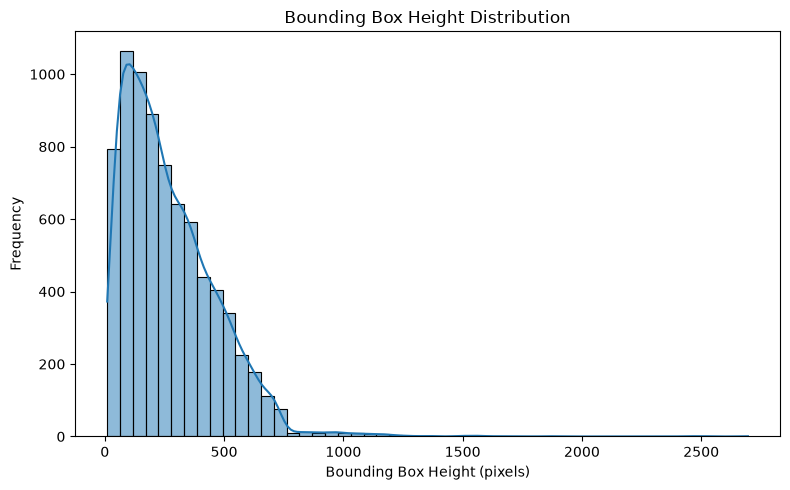

In [25]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=annotations_df,
    x="bbox_height",
    bins=50,
    kde=True
)

plt.title("Bounding Box Height Distribution")
plt.xlabel("Bounding Box Height (pixels)")
plt.ylabel("Frequency")

plt.tight_layout()

path = SECTION_2_RESULTS_DIR / "bbox_height_distribution.png"
plt.savefig(path, dpi=300, bbox_inches="tight")

plt.show()

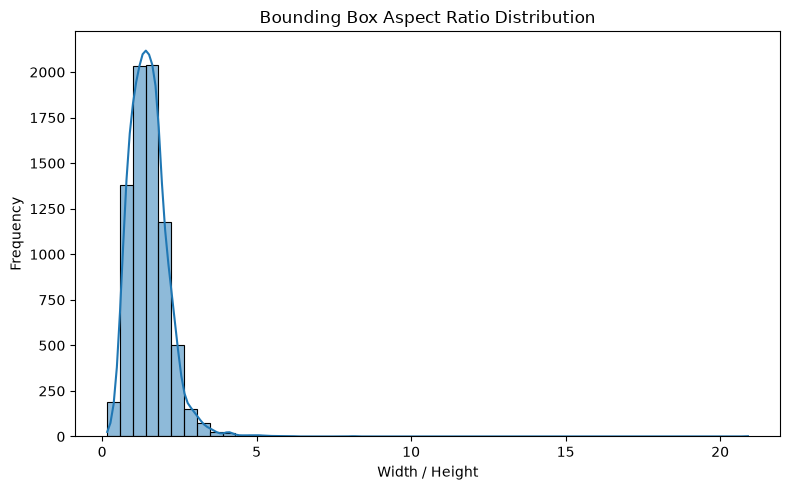

In [26]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=annotations_df,
    x="bbox_aspect_ratio",
    bins=50,
    kde=True
)

plt.title("Bounding Box Aspect Ratio Distribution")
plt.xlabel("Width / Height")
plt.ylabel("Frequency")

plt.tight_layout()

path = SECTION_2_RESULTS_DIR / "bbox_aspect_ratio_distribution.png"
plt.savefig(path, dpi=300, bbox_inches="tight")

plt.show()

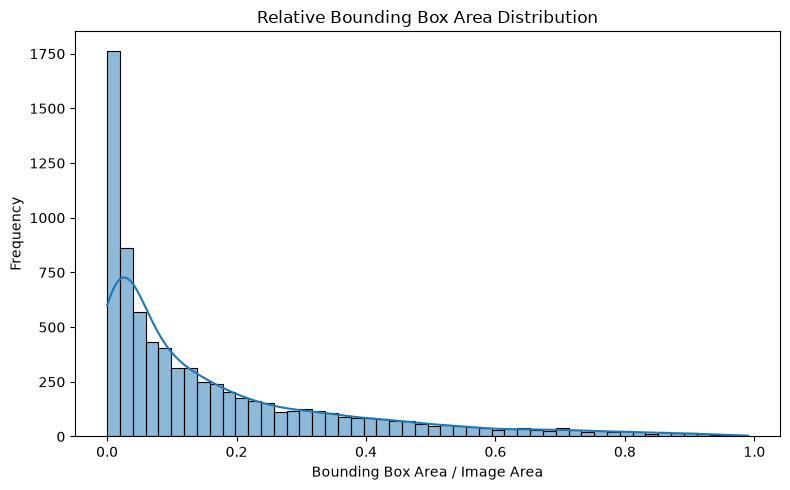

In [27]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=annotations_df,
    x="bbox_area_ratio",
    bins=50,
    kde=True
)

plt.title("Relative Bounding Box Area Distribution")
plt.xlabel("Bounding Box Area / Image Area")
plt.ylabel("Frequency")

plt.tight_layout()

path = SECTION_2_RESULTS_DIR / "bbox_area_ratio_distribution.png"
plt.savefig(path, dpi=300, bbox_inches="tight")

plt.show()

#### Train/Validation/Test Split

The dataset is divided into training, validation, and test sets using a 70:15:15 ratio.

The split is performed at the image level rather than at the bounding-box level. This ensures that all annotations belonging to the same image remain within the same subset and prevents image-level data leakage.

A fixed random seed is used to make the split reproducible. The same split will be used for all three detector families to ensure a fair comparison.

In [28]:
image_df = (
    annotations_df[
        ["filename", "width", "height"]
    ]
    .drop_duplicates("filename")
    .reset_index(drop=True)
)

print("Total unique images:", len(image_df))

display(image_df.head())

Total unique images: 3929


,filename,width,height
0,00001.jpg,720,576
1,00002.jpg,1280,720
2,00010.jpg,1280,720
3,00011.jpg,1280,720
4,00018.jpg,1280,720


In [29]:
# 70% Train, 15% Validation, 15% Test

train_df, temp_df = train_test_split(
    image_df,
    test_size=0.30,
    random_state=SEED,
    shuffle=True
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    shuffle=True
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

split_df = pd.concat(
    [
        train_df,
        val_df,
        test_df
    ],
    ignore_index=True
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Total images:", len(split_df))

Training images: 2750
Validation images: 589
Test images: 590
Total images: 3929


In [30]:
train_images = set(train_df["filename"])
val_images = set(val_df["filename"])
test_images = set(test_df["filename"])

train_val_overlap = train_images & val_images
train_test_overlap = train_images & test_images
val_test_overlap = val_images & test_images

print("Train-Val overlap:", len(train_val_overlap))
print("Train-Test overlap:", len(train_test_overlap))
print("Val-Test overlap:", len(val_test_overlap))

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print("\nNo image-level data leakage detected.")

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0

No image-level data leakage detected.


In [31]:
SPLITS_DIR = Path("./splits")

split_df.to_csv(
    SPLITS_DIR / "image_splits.csv",
    index=False
)

train_df[["filename"]].to_csv(
    SPLITS_DIR / "train.csv",
    index=False
)

val_df[["filename"]].to_csv(
    SPLITS_DIR / "val.csv",
    index=False
)

test_df[["filename"]].to_csv(
    SPLITS_DIR / "test.csv",
    index=False
)

print(
    "Split files saved to:",
    SPLITS_DIR
)

Split files saved to: splits


In [32]:
annotations_with_split = annotations_df.merge(
    split_df[["filename", "split"]],
    on="filename",
    how="left"
)

split_class_distribution = pd.crosstab(
    annotations_with_split["split"],
    annotations_with_split["class_name"]
)

split_class_distribution = (
    split_class_distribution[
        ["Excavator", "Dozer", "Dump Truck"]
    ]
)

display(split_class_distribution)

class_name,Excavator,Dozer,Dump Truck
split,,,
test,429,156,555
train,1943,806,2618
val,418,161,528


#### Ground-Truth Visualization

Six sample images are selected from the dataset and visualized with their ground-truth bounding boxes. Each bounding box is annotated with its corresponding equipment class.

The visualization provides a qualitative inspection of the dataset and helps verify that the image files, class labels, and bounding-box coordinates have been loaded correctly.

In [35]:
def plot_ground_truth_grid(image_filenames, annotations, image_dir=IMAGE_DIR, rows=2, cols=3, figsize=(18, 10)):

    fig, axes = plt.subplots(rows, cols, figsize=figsize)

    axes = np.array(axes).reshape(-1)

    for ax, image_filename in zip(axes, image_filenames):

        image_path = image_dir / image_filename

        image = cv2.imread(
            str(image_path)
        )

        if image is None:
            ax.set_title(
                f"Image not found:\n{image_filename}"
            )
            ax.axis("off")
            continue

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        ax.imshow(image)

        image_annotations = annotations[
            annotations["filename"]
            == image_filename
        ]

        for _, row in image_annotations.iterrows():

            xmin = int(row["xmin"])
            ymin = int(row["ymin"])
            xmax = int(row["xmax"])
            ymax = int(row["ymax"])

            rectangle = plt.Rectangle(
                (xmin, ymin),
                xmax - xmin,
                ymax - ymin,
                fill=False,
                linewidth=2
            )

            ax.add_patch(rectangle)

            ax.text(
                xmin,
                max(ymin - 5, 0),
                row["class_name"],
                fontsize=9,
                bbox=dict(
                    facecolor="white",
                    alpha=0.7
                )
            )

        ax.set_title(
            image_filename
        )

        ax.axis("off")

    for ax in axes[len(image_filenames):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [36]:
sample_images = (
    annotations_df["filename"]
    .drop_duplicates()
    .sample(
        n=6,
        random_state=SEED
    )
    .tolist()
)

print("Selected sample images:")

for image_name in sample_images:
    print(image_name)

Selected sample images:
08292.jpg
06837.jpg
09322.jpg
05416.jpg
08207.jpg
06207.jpg


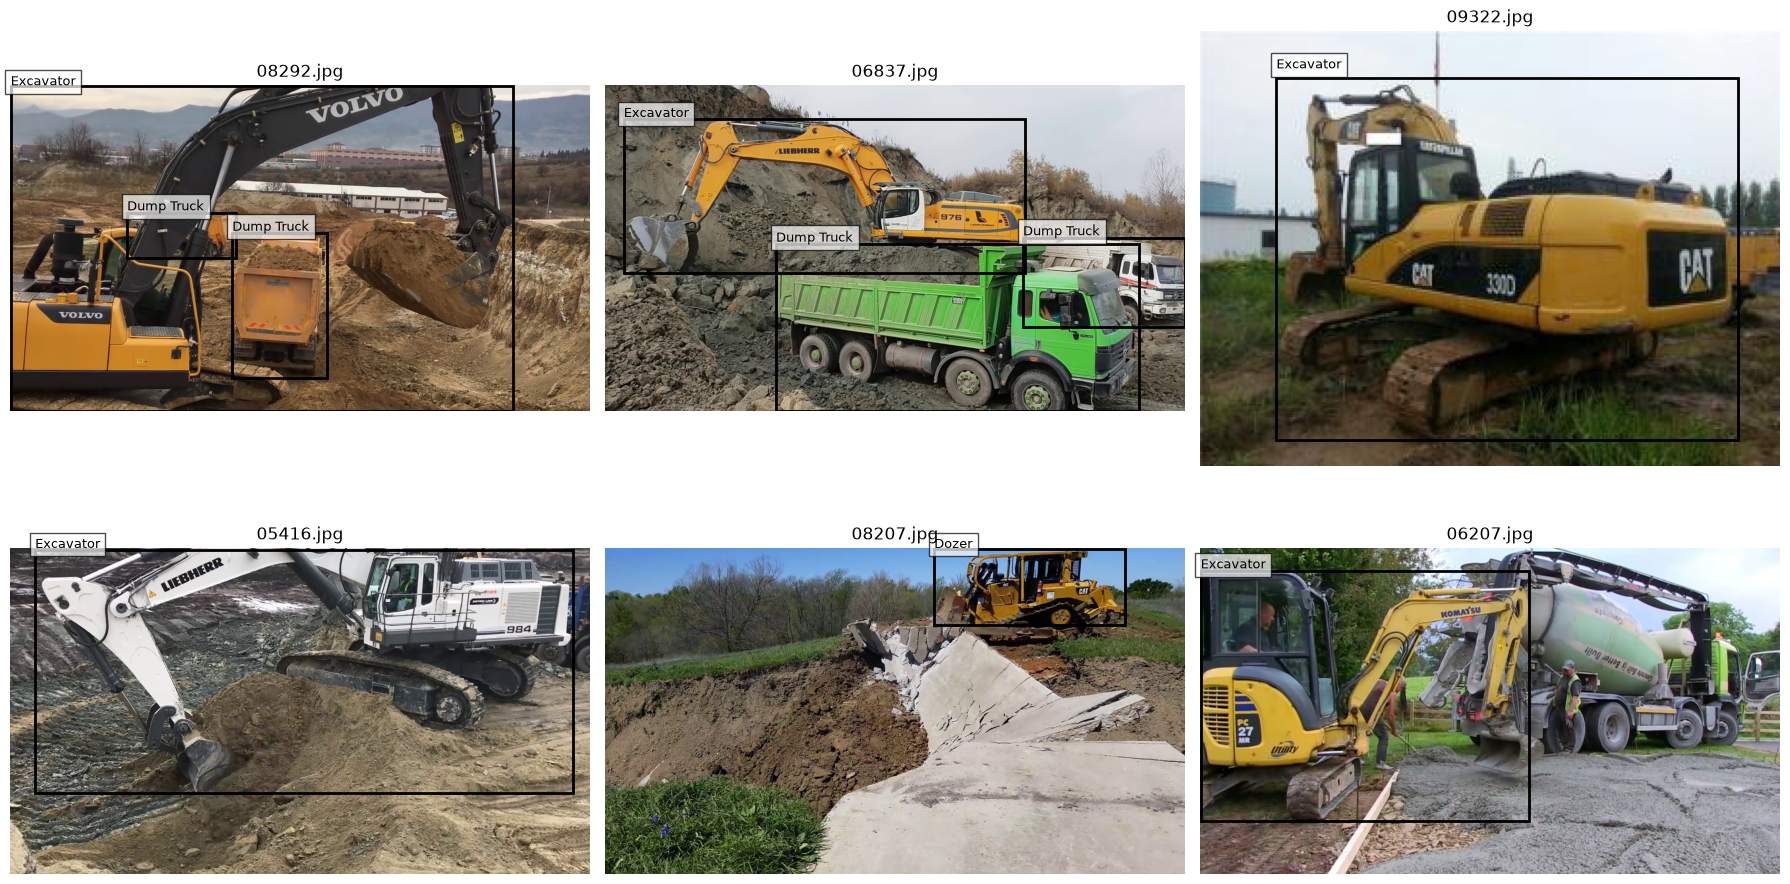

In [37]:
plot_ground_truth_grid(
    image_filenames=sample_images,
    annotations=annotations_df
)

In [38]:
pd.DataFrame({
    "filename": sample_images
}).to_csv(
    SECTION_2_RESULTS_DIR / "ground_truth_samples.csv",
    index=False
)

print(
    "Saved:",
    SECTION_2_RESULTS_DIR / "ground_truth_samples.csv"
)

Saved: notebook_results\dataset_acquisition_and_preprocessing\ground_truth_samples.csv


### Two-Stage Object Detection — Faster R-CNN

## 3.1 Detector Selection and Configuration

Faster R-CNN is selected as the two-stage object detector for the ACID dataset. Faster R-CNN follows a two-stage detection architecture in which a Region Proposal Network (RPN) first generates candidate object regions, followed by a region-based detector that classifies the proposals and refines their bounding boxes.

For this dataset, Faster R-CNN is suitable because the task involves detecting three visually distinct construction-equipment categories with bounding-box annotations. The two-stage architecture provides explicit region proposal and bounding-box refinement, which is useful for accurately localizing construction vehicles in varying image scales and backgrounds.

The model is initialized using a pretrained Faster R-CNN
ResNet-50-FPN checkpoint and fine-tuned on the three ACID classes.

In [39]:
NUM_CLASSES = 4

CLASS_TO_ID = {
    "Excavator": 1,
    "Dozer": 2,
    "Dump Truck": 3
}

ID_TO_CLASS = {
    1: "Excavator",
    2: "Dozer",
    3: "Dump Truck"
}

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Device: cuda
GPU: NVIDIA GeForce RTX 4070 Laptop GPU


In [40]:
class ACIDDetectionDataset(torch.utils.data.Dataset):

    def __init__(
        self,
        image_filenames,
        annotations,
        image_dir,
        transforms=None
    ):
        self.image_filenames = list(image_filenames)
        self.annotations = annotations
        self.image_dir = Path(image_dir)
        self.transforms = transforms

    def __len__(self):
        return len(self.image_filenames)

    def __getitem__(self, index):

        filename = self.image_filenames[index]

        image_path = self.image_dir / filename

        image = Image.open(
            image_path
        ).convert("RGB")

        image_annotations = self.annotations[
            self.annotations["filename"] == filename
        ]

        boxes = []
        labels = []
        areas = []

        for _, row in image_annotations.iterrows():

            xmin = float(row["xmin"])
            ymin = float(row["ymin"])
            xmax = float(row["xmax"])
            ymax = float(row["ymax"])

            boxes.append([
                xmin,
                ymin,
                xmax,
                ymax
            ])

            labels.append(
                CLASS_TO_ID[row["class_name"]]
            )

            areas.append(
                (xmax - xmin) *
                (ymax - ymin)
            )

        boxes = torch.as_tensor(
            boxes,
            dtype=torch.float32
        )

        labels = torch.as_tensor(
            labels,
            dtype=torch.int64
        )

        areas = torch.as_tensor(
            areas,
            dtype=torch.float32
        )

        image_id = torch.tensor(
            [index],
            dtype=torch.int64
        )

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": image_id,
            "area": areas,
            "iscrowd": torch.zeros(
                len(boxes),
                dtype=torch.int64
            )
        }

        image = transforms.ToTensor()(image)

        if self.transforms is not None:
            image, target = self.transforms(
                image,
                target
            )

        return image, target

In [41]:
def detection_collate_fn(batch):

    images, targets = zip(*batch)

    return (
        list(images),
        list(targets)
    )

In [42]:
train_dataset = ACIDDetectionDataset(
    image_filenames=train_df["filename"],
    annotations=annotations_df,
    image_dir=IMAGE_DIR
)

val_dataset = ACIDDetectionDataset(
    image_filenames=val_df["filename"],
    annotations=annotations_df,
    image_dir=IMAGE_DIR
)

test_dataset = ACIDDetectionDataset(
    image_filenames=test_df["filename"],
    annotations=annotations_df,
    image_dir=IMAGE_DIR
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Training images: 2750
Validation images: 589
Test images: 590


In [43]:
BATCH_SIZE = 2

NUM_WORKERS = 0

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    collate_fn=detection_collate_fn
)

val_loader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=detection_collate_fn
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=detection_collate_fn
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


In [44]:
weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT

model = fasterrcnn_resnet50_fpn(
    weights=weights
)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to C:\Users\VASANTHARAN/.cache\torch\hub\checkpoints\fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:14<00:00, 11.5MB/s] 


In [45]:
from torchvision.models.detection.faster_rcnn import (
    FastRCNNPredictor
)

in_features = (
    model.roi_heads.box_predictor.cls_score.in_features
)

model.roi_heads.box_predictor = (
    FastRCNNPredictor(
        in_features,
        NUM_CLASSES
    )
)

model = model.to(DEVICE)

print("Faster R-CNN configured for:")
print("Number of classes:", NUM_CLASSES)
print("Classes:", list(ID_TO_CLASS.values()))

Faster R-CNN configured for:
Number of classes: 4
Classes: ['Excavator', 'Dozer', 'Dump Truck']


#### Model Fine-Tuning

The pretrained Faster R-CNN ResNet-50-FPN model is fine-tuned on the ACID training split. The model parameters are optimized using stochastic gradient descent with momentum.

The training configuration is kept fixed and recorded so that the experimental setup can be reproduced and compared with the other detector families.

In [46]:
LEARNING_RATE = 0.005
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0005
NUM_EPOCHS = 10

print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", NUM_EPOCHS)
print("Optimizer: SGD")
print("Momentum:", MOMENTUM)
print("Weight decay:", WEIGHT_DECAY)

Learning rate: 0.005
Batch size: 2
Epochs: 10
Optimizer: SGD
Momentum: 0.9
Weight decay: 0.0005


In [47]:
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY
)

lr_scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

In [48]:
def train_one_epoch(
    model,
    data_loader,
    optimizer,
    device,
    epoch
):

    model.train()

    running_loss = 0.0

    progress_bar = tqdm(
        data_loader,
        desc=f"Epoch {epoch}"
    )

    for images, targets in progress_bar:

        images = [
            image.to(device)
            for image in images
        ]

        targets = [
            {
                key: value.to(device)
                for key, value in target.items()
            }
            for target in targets
        ]

        optimizer.zero_grad()

        loss_dict = model(
            images,
            targets
        )

        total_loss = sum(
            loss for loss in loss_dict.values()
        )

        total_loss.backward()

        optimizer.step()

        running_loss += (
            total_loss.item()
        )

        progress_bar.set_postfix(
            loss=f"{total_loss.item():.4f}"
        )

    epoch_loss = (
        running_loss /
        len(data_loader)
    )

    return epoch_loss

In [49]:
model.eval()

FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

In [50]:
@torch.no_grad()
def calculate_validation_loss(
    model,
    data_loader,
    device
):

    model.train()

    running_loss = 0.0

    for images, targets in data_loader:

        images = [
            image.to(device)
            for image in images
        ]

        targets = [
            {
                key: value.to(device)
                for key, value in target.items()
            }
            for target in targets
        ]

        loss_dict = model(
            images,
            targets
        )

        total_loss = sum(
            loss for loss in loss_dict.values()
        )

        running_loss += (
            total_loss.item()
        )

    validation_loss = (
        running_loss /
        len(data_loader)
    )

    return validation_loss

In [51]:
train_losses = []
val_losses = []

CHECKPOINTS_DIR = Path("./checkpoints")

CHECKPOINTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

training_start_time = time.time()

for epoch in range(
    1,
    NUM_EPOCHS + 1
):

    epoch_start_time = time.time()

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        DEVICE,
        epoch
    )

    val_loss = calculate_validation_loss(
        model,
        val_loader,
        DEVICE
    )

    lr_scheduler.step()

    train_losses.append(
        train_loss
    )

    val_losses.append(
        val_loss
    )

    epoch_time = (
        time.time()
        - epoch_start_time
    )

    print(
        f"\nEpoch {epoch}/{NUM_EPOCHS}"
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Validation Loss: {val_loss:.4f}"
    )

    print(
        f"Epoch Time: {epoch_time:.2f} seconds"
    )

Epoch 1: 100%|██████████| 1375/1375 [09:48<00:00,  2.34it/s, loss=0.1008]



Epoch 1/10
Train Loss: 0.2508
Validation Loss: 0.1995
Epoch Time: 661.81 seconds


Epoch 2: 100%|██████████| 1375/1375 [09:08<00:00,  2.51it/s, loss=0.0868]



Epoch 2/10
Train Loss: 0.1694
Validation Loss: 0.1788
Epoch Time: 611.54 seconds


Epoch 3: 100%|██████████| 1375/1375 [09:03<00:00,  2.53it/s, loss=0.0754]


...


Epoch 8/10
Train Loss: 0.0767
Validation Loss: 0.1543
Epoch Time: 609.28 seconds


Epoch 9: 100%|██████████| 1375/1375 [09:05<00:00,  2.52it/s, loss=0.0304]



Epoch 9/10
Train Loss: 0.0762
Validation Loss: 0.1545
Epoch Time: 610.20 seconds


Epoch 10: 100%|██████████| 1375/1375 [09:04<00:00,  2.52it/s, loss=0.0437]



Epoch 10/10
Train Loss: 0.0758
Validation Loss: 0.1544
Epoch Time: 608.27 seconds


In [52]:
training_time = (
    time.time()
    - training_start_time
)

checkpoint_path = (
    CHECKPOINTS_DIR /
    "faster_rcnn_resnet50_fpn.pth"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_losses": train_losses,
        "val_losses": val_losses,
        "epoch": NUM_EPOCHS
    },
    checkpoint_path
)

print(
    f"Training completed in "
    f"{training_time / 60:.2f} minutes"
)

print(
    "Checkpoint saved:",
    checkpoint_path
)

Training completed in 102.37 minutes
Checkpoint saved: checkpoints\faster_rcnn_resnet50_fpn.pth


#### Training and Validation Loss

The training and validation loss curves are plotted to monitor optimization and convergence of the Faster R-CNN model.

In [ ]:
CHECKPOINTS_DIR = Path("./checkpoints")
checkpoint = torch.load(
    CHECKPOINTS_DIR / "faster_rcnn_resnet50_fpn.pth",
    map_location=DEVICE
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

train_losses = checkpoint["train_losses"]
val_losses = checkpoint["val_losses"]

print("Completed epochs:", checkpoint["epoch"])
print("Training loss entries:", len(train_losses))
print("Validation loss entries:", len(val_losses))

In [53]:
SECTION_3_RESULTS_DIR = (
    RESULTS_DIR / "two_stage_faster_rcnn"
)

SECTION_3_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

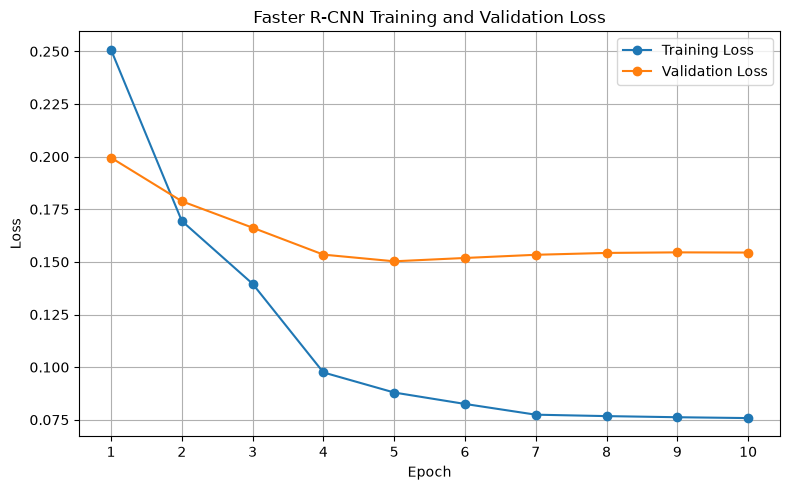

Saved: notebook_results\two_stage_faster_rcnn\faster_rcnn_loss_curve.png


In [54]:
plt.figure(figsize=(8, 5))

epochs = range(
    1,
    NUM_EPOCHS + 1
)

plt.plot(
    epochs,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(
    "Faster R-CNN Training and Validation Loss"
)

plt.xticks(
    list(epochs)
)

plt.legend()
plt.grid(True)

plt.tight_layout()

loss_curve_path = (
    SECTION_3_RESULTS_DIR /
    "faster_rcnn_loss_curve.png"
)

plt.savefig(
    loss_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    loss_curve_path
)

#### Validation and Evaluation

The trained Faster R-CNN model is evaluated on the validation split. Detection performance is measured using mean Average Precision (mAP) at IoU 0.50 and mAP averaged over IoU thresholds from 0.50 to 0.95.

Average Precision is also reported separately for Excavator, Dozer, and Dump Truck to identify differences in detection performance between the three equipment categories.

In [ ]:
@torch.no_grad()
def collect_predictions(
    model,
    data_loader,
    device
):

    model.eval()

    all_predictions = []
    all_targets = []

    for images, targets in tqdm(
        data_loader,
        desc="Evaluating"
    ):

        images = [
            image.to(device)
            for image in images
        ]

        predictions = model(images)

        predictions_cpu = [
            {
                key: value.cpu()
                for key, value in prediction.items()
            }
            for prediction in predictions
        ]

        targets_cpu = [
            {
                key: value.cpu()
                for key, value in target.items()
            }
            for target in targets
        ]

        all_predictions.extend(
            predictions_cpu
        )

        all_targets.extend(
            targets_cpu
        )

    return (
        all_predictions,
        all_targets
    )

In [ ]:
validation_predictions, validation_targets = (
    collect_predictions(
        model,
        val_loader,
        DEVICE
    )
)

print(
    "Validation images evaluated:",
    len(validation_predictions)
)

In [ ]:
map_metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    class_metrics=True
)

map_metric.update(
    validation_predictions,
    validation_targets
)

map_results = map_metric.compute()

print(
    "mAP@0.5:",
    map_results["map_50"].item()
)

print(
    "mAP@0.5:0.95:",
    map_results["map"].item()
)

In [ ]:
print("Class IDs:")
print(map_results["classes"])

print("\nPer-class AP:")
print(map_results["map_per_class"])

In [ ]:
class_ids = (
    map_results["classes"]
    .tolist()
)

per_class_ap = (
    map_results["map_per_class"]
    .tolist()
)

per_class_ap50 = (
    map_results["mar_100_per_class"]
    if "mar_100_per_class" in map_results
    else None
)

#### Quantitative Results

The validation performance of Faster R-CNN is summarized using
mAP@0.5 and mAP@0.5:0.95. Per-class Average Precision is reported for
Excavator, Dozer, and Dump Truck.

The training configuration, computational hardware, and training time
are also recorded to provide a reproducible description of the
experiment.

In [ ]:
# Hardware information

if torch.cuda.is_available():

    gpu_name = torch.cuda.get_device_name(0)

else:

    gpu_name = "CPU"

results_summary = pd.DataFrame({
    "Detector": [
        "Faster R-CNN ResNet-50-FPN"
    ],
    "Pretrained Checkpoint": [
        "COCO"
    ],
    "Learning Rate": [
        LEARNING_RATE
    ],
    "Batch Size": [
        BATCH_SIZE
    ],
    "Epochs": [
        NUM_EPOCHS
    ],
    "Optimizer": [
        "SGD"
    ],
    "Hardware": [
        gpu_name
    ],
    "Training Time (min)": [
        training_time / 60
    ],
    "mAP@0.5": [
        map_results["map_50"].item()
    ],
    "mAP@0.5:0.95": [
        map_results["map"].item()
    ]
})

display(results_summary)

In [ ]:
results_summary.to_csv(
    SECTION_3_RESULTS_DIR /
    "faster_rcnn_results.csv",
    index=False
)

#### Detection Examples

In [ ]:
def visualize_detection(
    image_filename,
    annotations,
    predictions,
    image_dir=IMAGE_DIR,
    score_threshold=0.5,
    figsize=(10, 7)
):

    image_path = image_dir / image_filename

    image = Image.open(
        image_path
    ).convert("RGB")

    image = np.array(image)

    plt.figure(figsize=figsize)

    plt.imshow(image)

    # Ground-truth boxes
    gt_annotations = annotations[
        annotations["filename"]
        == image_filename
    ]

    for _, row in gt_annotations.iterrows():

        xmin = int(row["xmin"])
        ymin = int(row["ymin"])
        xmax = int(row["xmax"])
        ymax = int(row["ymax"])

        rectangle = plt.Rectangle(
            (xmin, ymin),
            xmax - xmin,
            ymax - ymin,
            fill=False,
            linewidth=2
        )

        plt.gca().add_patch(
            rectangle
        )

        plt.text(
            xmin,
            max(ymin - 5, 0),
            f"GT: {row['class_name']}",
            fontsize=9,
            bbox=dict(
                facecolor="white",
                alpha=0.7
            )
        )

    # Predicted boxes
    boxes = predictions["boxes"]
    labels = predictions["labels"]
    scores = predictions["scores"]

    for box, label, score in zip(
        boxes,
        labels,
        scores
    ):

        if score < score_threshold:
            continue

        xmin, ymin, xmax, ymax = (
            box.tolist()
        )

        rectangle = plt.Rectangle(
            (xmin, ymin),
            xmax - xmin,
            ymax - ymin,
            fill=False,
            linewidth=2,
            linestyle="--"
        )

        plt.gca().add_patch(
            rectangle
        )

        class_name = ID_TO_CLASS.get(
            int(label),
            "Unknown"
        )

        plt.text(
            xmin,
            ymax,
            f"{class_name}: {score:.2f}",
            fontsize=9,
            bbox=dict(
                facecolor="white",
                alpha=0.7
            )
        )

    plt.title(
        f"Faster R-CNN: {image_filename}"
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()

In [ ]:
val_filenames = val_df[
    "filename"
].tolist()

print(
    "Validation images:",
    len(val_filenames)
)

In [ ]:
validation_prediction_map = {
    filename: prediction
    for filename, prediction in zip(
        val_filenames,
        validation_predictions
    )
}

#### Quantitative Success/Failure selection

In [ ]:
def calculate_iou(
    box_a,
    box_b
):

    xa1, ya1, xa2, ya2 = box_a
    xb1, yb1, xb2, yb2 = box_b

    intersection_x1 = max(
        xa1,
        xb1
    )

    intersection_y1 = max(
        ya1,
        yb1
    )

    intersection_x2 = min(
        xa2,
        xb2
    )

    intersection_y2 = min(
        ya2,
        yb2
    )

    intersection_width = max(
        0,
        intersection_x2 -
        intersection_x1
    )

    intersection_height = max(
        0,
        intersection_y2 -
        intersection_y1
    )

    intersection_area = (
        intersection_width *
        intersection_height
    )

    area_a = (
        (xa2 - xa1) *
        (ya2 - ya1)
    )

    area_b = (
        (xb2 - xb1) *
        (yb2 - yb1)
    )

    union_area = (
        area_a +
        area_b -
        intersection_area
    )

    if union_area == 0:
        return 0.0

    return (
        intersection_area /
        union_area
    )

In [ ]:
def evaluate_detection_example(
    filename,
    prediction,
    annotations,
    iou_threshold=0.5,
    score_threshold=0.5
):

    gt = annotations[
        annotations["filename"] == filename
    ]

    gt_boxes = gt[
        [
            "xmin",
            "ymin",
            "xmax",
            "ymax"
        ]
    ].values

    gt_labels = [
        CLASS_TO_ID[
            class_name
        ]
        for class_name in gt["class_name"]
    ]

    predicted_boxes = (
        prediction["boxes"].numpy()
    )

    predicted_labels = (
        prediction["labels"].numpy()
    )

    predicted_scores = (
        prediction["scores"].numpy()
    )

    valid_predictions = (
        predicted_scores >= score_threshold
    )

    predicted_boxes = predicted_boxes[
        valid_predictions
    ]

    predicted_labels = predicted_labels[
        valid_predictions
    ]

    matched = 0

    for gt_box, gt_label in zip(
        gt_boxes,
        gt_labels
    ):

        for pred_box, pred_label in zip(
            predicted_boxes,
            predicted_labels
        ):

            if gt_label != pred_label:
                continue

            iou = calculate_iou(
                gt_box,
                pred_box
            )

            if iou >= iou_threshold:
                matched += 1
                break

    return matched, len(gt_boxes)

In [ ]:
example_scores = []

for filename in val_filenames:

    matched, total_gt = (
        evaluate_detection_example(
            filename,
            validation_prediction_map[filename],
            annotations_df
        )
    )

    example_scores.append({
        "filename": filename,
        "matched": matched,
        "ground_truth_objects": total_gt
    })

example_scores_df = pd.DataFrame(
    example_scores
)

display(
    example_scores_df.head()
)

In [ ]:
successful_examples = (
    example_scores_df[
        example_scores_df["matched"]
        == example_scores_df["ground_truth_objects"]
    ]
    .head(3)
)

failed_examples = (
    example_scores_df[
        example_scores_df["matched"]
        < example_scores_df["ground_truth_objects"]
    ]
    .head(3)
)

print("Successful examples:")
display(successful_examples)

print("Failed examples:")
display(failed_examples)

In [ ]:
print("Successful Detection Examples")

for filename in successful_examples["filename"]:

    visualize_detection(
        filename,
        annotations_df,
        validation_prediction_map[filename]
    )

In [ ]:
print("Failed Detection Examples")

for filename in failed_examples["filename"]:

    visualize_detection(
        filename,
        annotations_df,
        validation_prediction_map[filename]
    )